<a href="https://colab.research.google.com/github/alightnessaron-afk/COU07506-labs./blob/main/COU07506_Week04_240242425544.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

COU 07506 – Digital Signal Processing

Week 4: z-Transform Laboratory – Poles, Zeros and Stability

Name: Lightness Aron Japheti

Registration Number: 240242425544

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

In [3]:
def zplane(b, a, ax=None):

    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    theta = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(theta), np.sin(theta), "k--",
            label="Unit circle")

    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="Zeros")

    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="Poles")

    ax.set_aspect("equal")

    ax.legend()

    ax.set_xlabel("Real")

    ax.set_ylabel("Imaginary")

    return z, p

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

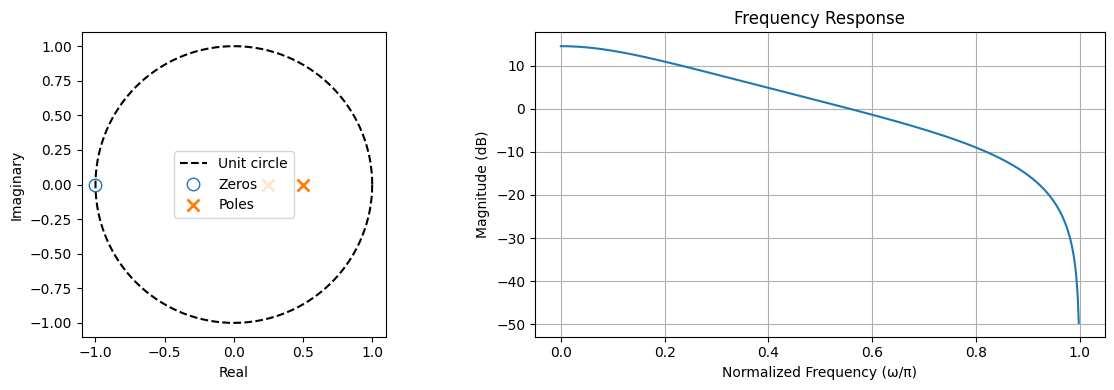

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [4]:
b = [1, 1]

a = [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))

ax2.set_title("Frequency Response")

ax2.set_xlabel("Normalized Frequency (ω/π)")

ax2.set_ylabel("Magnitude (dB)")

ax2.grid(True)

plt.tight_layout()

plt.show()

print("Zeros:", z)

print("Poles:", p)

print("Stable:", np.all(np.abs(p) < 1))

task 4.2

In [5]:
b = [1]
a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct terms:", k)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct terms: []


In [6]:
n = np.arange(10)

x_pf = np.zeros(len(n))

for ri, pi in zip(r, p):

    x_pf += ri * pi**n

x_pf = x_pf.real

print("Partial fraction response:")
print(x_pf)

Partial fraction response:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]


In [7]:
impulse = np.zeros(10)

impulse[0] = 1

x_filter = signal.lfilter(b, a, impulse)

print("Partial fraction:", x_pf)

print("Using lfilter:", x_filter)

print("Results match:", np.allclose(x_pf, x_filter))

Partial fraction: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Using lfilter: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Results match: True


In [8]:
b = [1, 1]

a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

n = np.arange(10)

x_pf = sum(ri * pi**n for ri, pi in zip(r, p))

x_pf = np.real(x_pf)

x_theoretical = 6*(0.5**n) - 5*(0.25**n)

print("Partial fraction:", x_pf)

print("Theoretical:", x_theoretical)

print("Results match:", np.allclose(x_pf, x_theoretical))

Partial fraction: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Theoretical: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


task 4.3

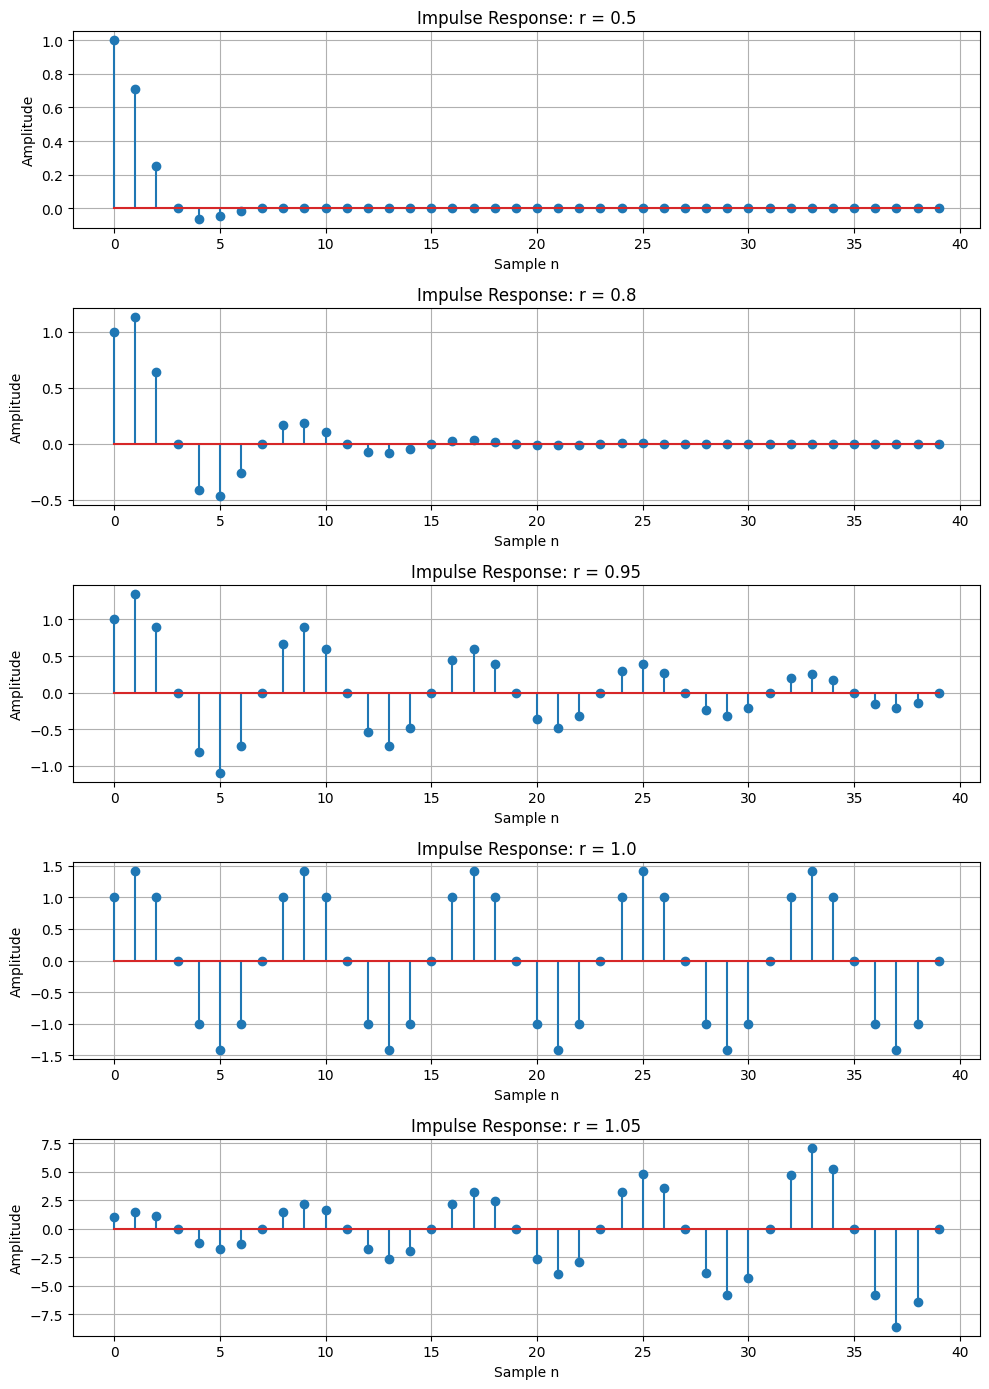

In [9]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

n = np.arange(40)

fig, axes = plt.subplots(5, 1, figsize=(10, 14))

for ax, r in zip(axes, r_values):

    b = [1]

    a = [1, -2*r*np.cos(np.pi/4), r**2]

    impulse = np.zeros(40)

    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    ax.stem(n, h)

    ax.set_title(f"Impulse Response: r = {r}")

    ax.set_xlabel("Sample n")

    ax.set_ylabel("Amplitude")

    ax.grid(True)

plt.tight_layout()

plt.show()

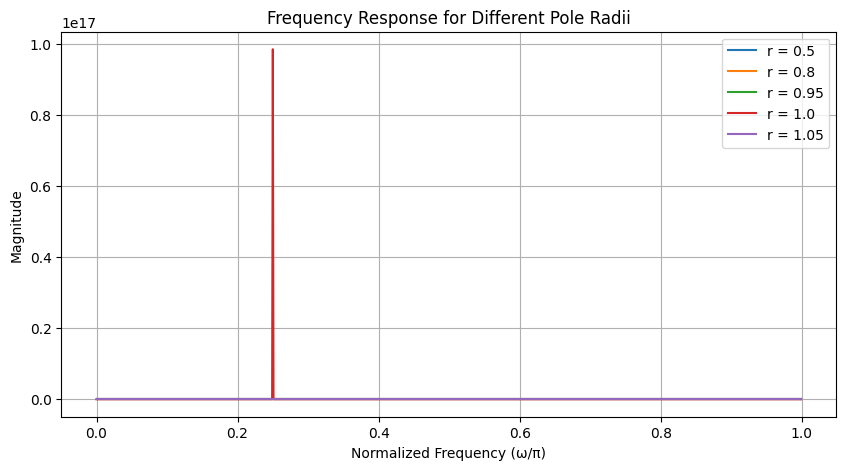

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

for r in r_values:

    b = [1]

    a = [1, -2*r*np.cos(np.pi/4), r**2]

    w, H = signal.freqz(b, a, worN=1024)

    magnitude = np.abs(H)

    ax.plot(w/np.pi, magnitude, label=f"r = {r}")

ax.set_title("Frequency Response for Different Pole Radii")

ax.set_xlabel("Normalized Frequency (ω/π)")

ax.set_ylabel("Magnitude")

ax.legend()

ax.grid(True)

plt.show()

task 4.4

In [11]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),

    "H2": ([1, 1], [1, -2.5, 1]),

    "H3": ([1], [1, 0.5, -0.5]),

    "H4": ([1, 0, 0, 0, -1], [1])
}

H1
Poles: [0.8+0.5j 0.8-0.5j]
Stable: True
----------------
H2
Poles: [2.  0.5]
Stable: False
----------------
H3
Poles: [-1.   0.5]
Stable: False
----------------
H4
Poles: []
Stable: True
----------------


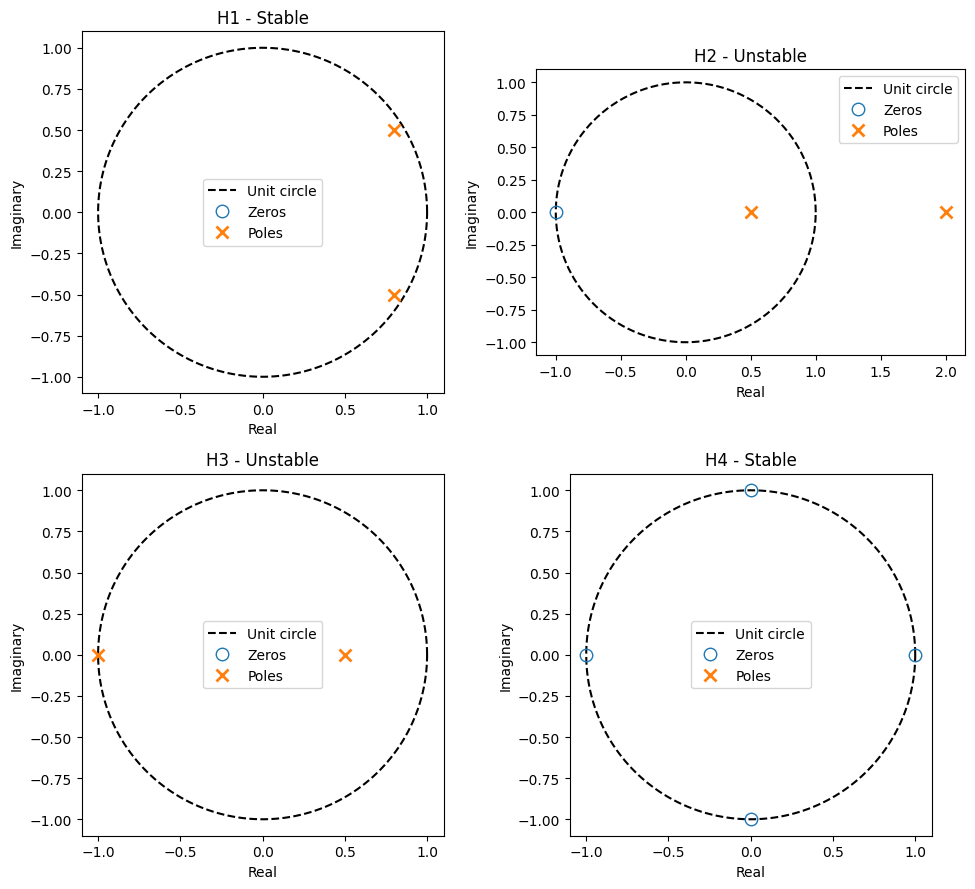

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, (b, a)) in zip(axes.flatten(), systems.items()):

    z, p = zplane(b, a, ax)

    stable = np.all(np.abs(p) < 1)

    ax.set_title(f"{name} - {'Stable' if stable else 'Unstable'}")

    print(name)

    print("Poles:", p)

    print("Stable:", stable)

    print("----------------")

plt.tight_layout()

plt.show()

task 4.5

In [13]:
fs = 8000

f0 = 1000

r = 0.97

theta = 2 * np.pi * f0 / fs

b = [1, 0, -1]

a = [
    1,
    -2*r*np.cos(theta),
    r**2
]

print("Numerator:", b)

print("Denominator:", a)

Numerator: [1, 0, -1]
Denominator: [1, np.float64(-1.3717871555019023), 0.9409]


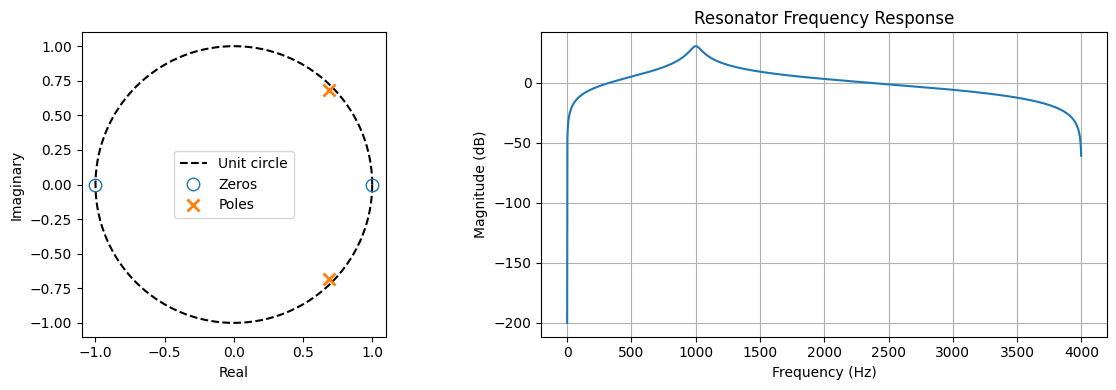

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable: True


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=2048, fs=fs)

ax2.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-10)))

ax2.set_title("Resonator Frequency Response")

ax2.set_xlabel("Frequency (Hz)")

ax2.set_ylabel("Magnitude (dB)")

ax2.grid(True)

plt.tight_layout()

plt.show()

print("Zeros:", z)

print("Poles:", p)

print("Stable:", np.all(np.abs(p) < 1))

In [15]:
from IPython.display import Audio, display

rng = np.random.default_rng(42)

white_noise = rng.standard_normal(8000)

output = signal.lfilter(b, a, white_noise)

print("Original white noise:")
display(Audio(white_noise, rate=fs))

print("Resonator output:")
display(Audio(output, rate=fs))

Original white noise:


Resonator output:


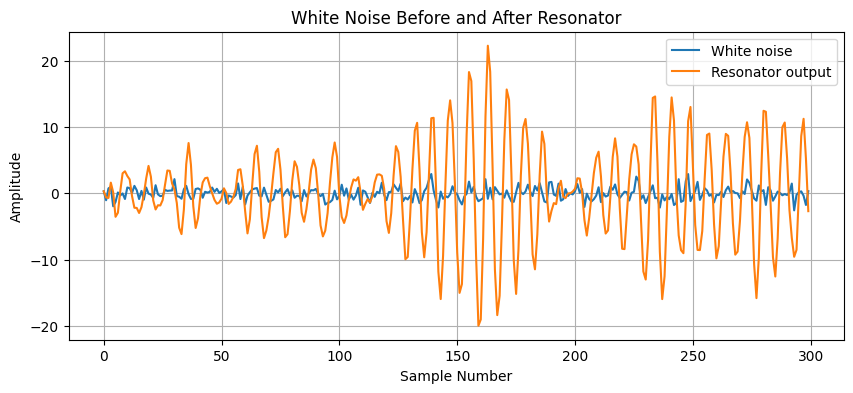

In [16]:
plt.figure(figsize=(10, 4))

plt.plot(white_noise[:300], label="White noise")

plt.plot(output[:300], label="Resonator output")

plt.title("White Noise Before and After Resonator")

plt.xlabel("Sample Number")

plt.ylabel("Amplitude")

plt.legend()

plt.grid(True)

plt.show()

Analysis questions

1. How does increasing pole radius affect resonance bandwidth?




As the pole radius approaches 1, the resonance peak becomes sharper and the bandwidth becomes narrower. When the pole radius is smaller, the resonance is broader.

2. What happens to the impulse response when a pole lies on the unit circle?



When a pole lies on the unit circle, the impulse response does not decay to zero. It may continue oscillating with constant amplitude. Therefore, the system is not BIBO stable.

3. Why do zeros at z = +1 and z = -1 make the resonator a band-pass filter?



The zero at z = +1 blocks DC components (0 Hz), while the zero at z = -1 blocks the Nyquist frequency (fs/2). The resonator emphasizes frequencies around 1 kHz, producing band-pass behaviour.